In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [2]:
# Load dataset
url = f"https://drive.google.com/uc?id=1sScVxMr5uk2DfmK7rA3z13O1-_oEL6p-"

df = pd.read_csv(url)

# Select features as requested: MOI, Seedling Stage, and temperature
features = ['MOI', 'Seedling Stage', 'temp']
X = df[features]

print("Dataset loaded successfully!")
print(f"Dimensions of the data used for clustering: {X.shape}")
print("\nFirst five rows of the feature data:")
print(X.head())

Dataset loaded successfully!
Dimensions of the data used for clustering: (16283, 3)

First five rows of the feature data:
   MOI  Seedling Stage  temp
0    1               2    25
1    2               2    26
2    3               2    27
3    4               2    28
4    5               2    29


In [3]:
# Standardize the data using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data standardization completed!")

Data standardization completed!


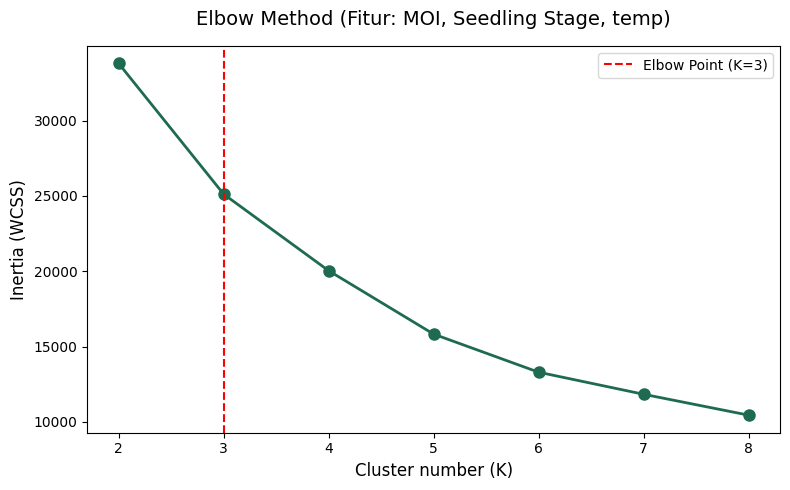

Inertia for each K:
K = 2: Inertia = 33800.25
K = 3: Inertia = 25122.56
K = 4: Inertia = 20039.50
K = 5: Inertia = 15829.88
K = 6: Inertia = 13300.40
K = 7: Inertia = 11834.63
K = 8: Inertia = 10448.15


In [4]:
# Calculate WCSS (Within-Cluster Sum of Squares) for different K values
inertia = []
K_range = range(2, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', color='#1e6b52', linewidth=2, markersize=8)
plt.axvline(x=3, color='r', linestyle='--', label='Elbow Point (K=3)')
plt.title('Elbow Method (Fitur: MOI, Seedling Stage, temp)', fontsize=14, pad=15)
plt.xlabel('Cluster number (K)', fontsize=12)
plt.ylabel('Inertia (WCSS)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

# Display the actual Inertia values
print("Inertia for each K:")
for k, ine in zip(K_range, inertia):
    print(f"K = {k}: Inertia = {ine:.2f}")

In [5]:
# Initialize and fit the model with K=3
K_OPTIMAL = 3
kmeans_model = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
df['Cluster'] = kmeans_model.fit_predict(X_scaled)

# Calculate the Silhouette Score
sil_score = silhouette_score(X_scaled, df['Cluster'])

print("="*55)
print("    CLUSTERING EVALUATION RESULTS (SILHOUETTE SCORE)     ")
print("="*55)
print(f"Number of Clusters (K)      : {K_OPTIMAL}")
print(f"Silhouette Score Value  : {sil_score:.4f}")

# Categorize the score interpretation
if sil_score > 0.7:
    interpretasi = "Very Good"
elif sil_score > 0.5:
    interpretasi = "Good"
elif sil_score > 0.25:
    interpretasi = "Average"
else:
    interpretasi = "Not so Good"

print(f"Interpretation Category   : {interpretasi}")
print("="*55)

# Display the number of data points per cluster
print("\nNumber of Data Rows Distribution Per Cluster:")
print(df['Cluster'].value_counts().sort_index())

    CLUSTERING EVALUATION RESULTS (SILHOUETTE SCORE)     
Number of Clusters (K)      : 3
Silhouette Score Value  : 0.3043
Interpretation Category   : Average

Number of Data Rows Distribution Per Cluster:
Cluster
0    5805
1    5320
2    5158
Name: count, dtype: int64


In [6]:
centroids = df.groupby('Cluster')[features].mean()
print("="*45)
print("CHARACTERISTICS OF EACH CLUSTER (CENTROID)")
print("="*45)
print(centroids.round(2))
print("="*45)

CHARACTERISTICS OF EACH CLUSTER (CENTROID)
           MOI  Seedling Stage   temp
Cluster                              
0        29.00            5.94  24.90
1        32.00            1.12  25.46
2        72.56            3.97  36.99


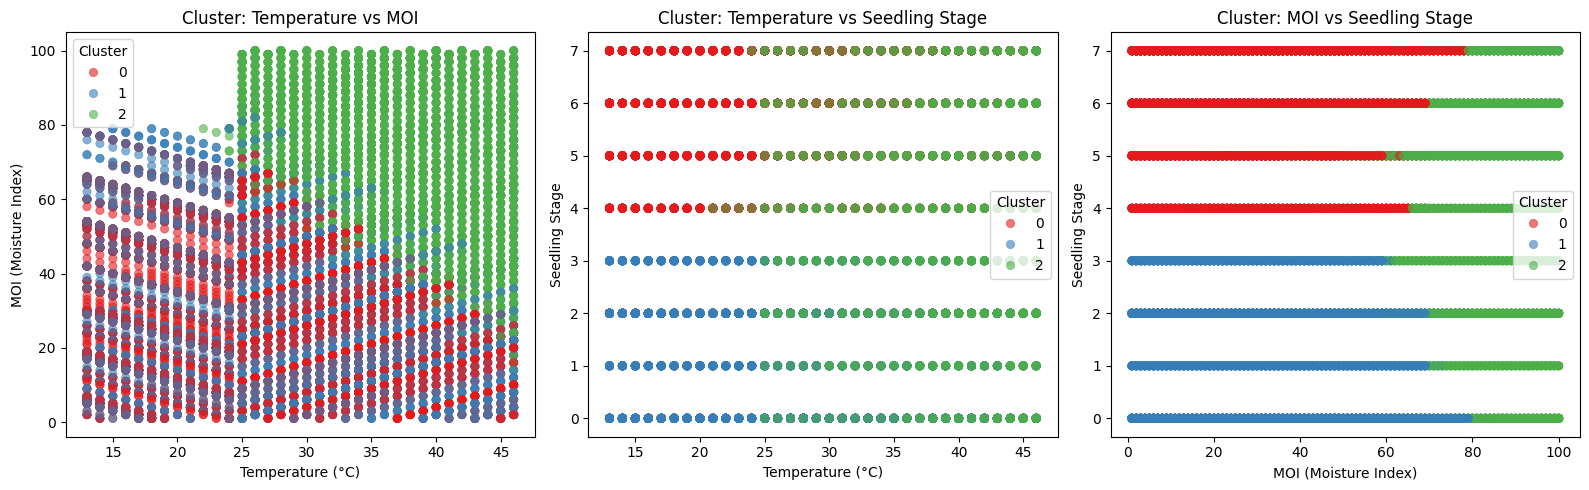

In [7]:
plt.figure(figsize=(16, 5))

# Hubungan 1: temp vs MOI
plt.subplot(1, 3, 1)
sns.scatterplot(data=df, x='temp', y='MOI', hue='Cluster', palette='Set1', alpha=0.6, edgecolor=None)
plt.title('Cluster: Temperature vs MOI', fontsize=12)
plt.xlabel('Temperature (°C)')
plt.ylabel('MOI (Moisture Index)')

# Hubungan 2: temp vs Seedling Stage
plt.subplot(1, 3, 2)
sns.scatterplot(data=df, x='temp', y='Seedling Stage', hue='Cluster', palette='Set1', alpha=0.6, edgecolor=None)
plt.title('Cluster: Temperature vs Seedling Stage', fontsize=12)
plt.xlabel('Temperature (°C)')
plt.ylabel('Seedling Stage')

# Hubungan 3: MOI vs Seedling Stage
plt.subplot(1, 3, 3)
sns.scatterplot(data=df, x='MOI', y='Seedling Stage', hue='Cluster', palette='Set1', alpha=0.6, edgecolor=None)
plt.title('Cluster: MOI vs Seedling Stage', fontsize=12)
plt.xlabel('MOI (Moisture Index)')
plt.ylabel('Seedling Stage')

plt.tight_layout()
plt.show()

In [8]:
import joblib

# Save the model using the correct variable name
joblib.dump(kmeans_model, "kmeans_model.pkl")

# Save the scaler
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']